In [1]:
!pip install catboost openpyxl joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.7 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import joblib

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from catboost import CatBoostClassifier

In [3]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df = pd.read_excel(
    "/content/drive/MyDrive/supreme_court_judgments_enhanced final.xlsx"
)

print("Dataset Shape:", df.shape)
print("\nTotal Columns:", len(df.columns))

Dataset Shape: (26688, 68)

Total Columns: 68


In [5]:
print("Primary Judge column:")
print(df["primary_judge"].value_counts().head(20))

print("\nTotal unique judges:", df["primary_judge"].nunique())

print("\nExpertise Area:")
print(df["primary_expertise_area"].value_counts())

print("\nMissing values:")
print(
    df[["primary_judge", "primary_expertise_area"]]
    .isnull()
    .sum()
)

Primary Judge column:
primary_judge
Nasir-ul-Mulk    1
Mushir Alam      1
Name: count, dtype: int64

Total unique judges: 2

Expertise Area:
primary_expertise_area
service    2
Name: count, dtype: int64

Missing values:
primary_judge             26686
primary_expertise_area    26686
dtype: int64


In [6]:
check_columns = [
    "case_type",
    "complexity_score",
    "estimated_duration_days",
    "number_of_parties",
    "case_age",
    "appeal_level"
]

print(df[check_columns].isnull().sum())

print("\nCase Types:")
print(df["case_type"].value_counts())

case_type                  0
complexity_score           0
estimated_duration_days    0
number_of_parties          0
case_age                   0
appeal_level               0
dtype: int64

Case Types:
case_type
civil             9822
criminal          5785
constitutional    4569
tax               4097
service           1305
election           458
family             410
corporate          225
uncategorized       17
Name: count, dtype: int64


In [7]:
def create_judge_recommendation(row):

    case_type = str(row["case_type"]).lower()

    if case_type == "civil":
        return "Civil Judge"

    elif case_type == "criminal":
        return "Criminal Judge"

    elif case_type == "constitutional":
        return "Constitutional Bench"

    elif case_type == "tax":
        return "Tax Judge"

    elif case_type == "service":
        return "Service Tribunal"

    elif case_type == "election":
        return "Election Tribunal"

    elif case_type == "family":
        return "Family Judge"

    elif case_type == "corporate":
        return "Commercial Judge"

    else:
        return "General Judge"


df["recommended_judge_type"] = df.apply(
    create_judge_recommendation,
    axis=1
)

print(df["recommended_judge_type"].value_counts())

recommended_judge_type
Civil Judge             9822
Criminal Judge          5785
Constitutional Bench    4569
Tax Judge               4097
Service Tribunal        1305
Election Tribunal        458
Family Judge             410
Commercial Judge         225
General Judge             17
Name: count, dtype: int64


In [8]:
features = [
    "complexity_score",
    "estimated_duration_days",
    "number_of_parties",
    "case_age",
    "appeal_level"
]

X = df[features]

y = df["recommended_judge_type"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.nunique())

Features Shape: (26688, 5)
Target Shape: (26688,)

Target Classes:
9


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data: (21350, 5)
Testing Data : (5338, 5)


In [10]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    loss_function="MultiClass",
    random_seed=42,
    verbose=100
)

model.fit(
    X_train,
    y_train,
    cat_features=["appeal_level"]
)

print("✅ Judge Recommendation Model Training Completed")

0:	learn: 1.5395781	total: 215ms	remaining: 1m 4s
100:	learn: 0.1721815	total: 9.9s	remaining: 19.5s
200:	learn: 0.1560410	total: 21s	remaining: 10.4s
299:	learn: 0.1470906	total: 31.9s	remaining: 0us
✅ Judge Recommendation Model Training Completed


In [11]:
y_pred = model.predict(X_test)

# Prediction ko 1D format me convert karna
y_pred = y_pred.flatten()

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 95.99 %


In [12]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

                      precision    recall  f1-score   support

         Civil Judge       0.93      0.97      0.95      1965
    Commercial Judge       0.00      0.00      0.00        45
Constitutional Bench       0.99      1.00      0.99       914
      Criminal Judge       0.98      1.00      0.99      1157
   Election Tribunal       0.00      0.00      0.00        92
        Family Judge       1.00      0.99      0.99        82
       General Judge       0.00      0.00      0.00         3
    Service Tribunal       1.00      0.99      0.99       261
           Tax Judge       0.95      0.98      0.97       819

            accuracy                           0.96      5338
           macro avg       0.65      0.66      0.65      5338
        weighted avg       0.94      0.96      0.95      5338



In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1913    0    2   13    0    0    0    0   37]
 [  41    0    0    0    0    0    0    0    4]
 [   0    0  912    2    0    0    0    0    0]
 [   0    0    4 1153    0    0    0    0    0]
 [  86    0    0    3    0    0    0    0    3]
 [   0    0    0    0    0   81    0    1    0]
 [   3    0    0    0    0    0    0    0    0]
 [   0    0    0    2    0    0    0  259    0]
 [   3    0    4    6    0    0    0    0  806]]


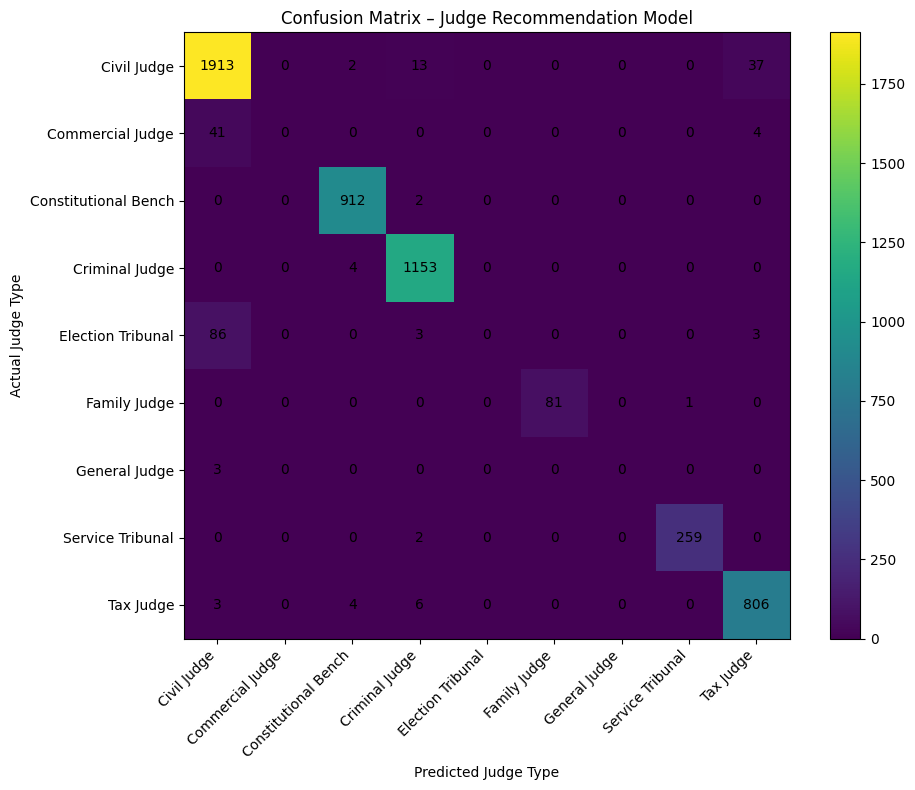

In [17]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    np.arange(len(model.classes_)),
    model.classes_,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(model.classes_)),
    model.classes_
)

plt.xlabel("Predicted Judge Type")
plt.ylabel("Actual Judge Type")
plt.title("Confusion Matrix – Judge Recommendation Model")

# Numbers inside the boxes
for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [18]:
import joblib

joblib.dump(
    model,
    "/content/drive/MyDrive/final_judge_recommendation_model.pkl"
)

print("✅ Final Model Saved Successfully")

✅ Final Model Saved Successfully


In [19]:
model_features = [
    "complexity_score",
    "estimated_duration_days",
    "number_of_parties",
    "case_age",
    "appeal_level"
]

joblib.dump(
    model_features,
    "/content/drive/MyDrive/judge_model_features.pkl"
)

print("✅ Feature List Saved Successfully")

✅ Feature List Saved Successfully
